# M00-2 | Graphs Exported in eval and train Mode Differ

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m00_export_basics/02_eval_vs_train.ipynb)

Take the same `ConvBnReLU`: calling `model.eval()` or `model.train()` before export gives different graphs.
This sets up M04 (fusion) and M06 (QAT):

| Flow | Mode | BatchNorm on the graph |
|---|---|---|
| PTQ | export after `model.eval()` → `prepare_pt2e` | uses running mean/var, a fixed affine transform that can be folded straight into the conv |
| QAT | export after `model.train()` → `prepare_qat_pt2e` | must compute this batch's statistics and update the running stats, so it has to stay on the graph |

- **A.** Export once in each mode and see where the graphs differ.
- **B.** How the arguments of the `batch_norm` node differ; whether the mode can still be switched after export.

In [1]:
#| include: false
# When running on Google Colab: download the course code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # let the notebook import this course's common/
    os.chdir(f"{repo}/en/m00_export_basics")

In [2]:
import torch
from torch.export import export

from common.graph_utils import diff_ops
from common.models import example_inputs, get_model
from common.pt2e import quiet
from common.viz import draw_stages, table

quiet()
_ = torch.manual_seed(0)

## A. Export Once in Each Mode

In [3]:
def export_in_mode(train: bool):
    model = get_model("conv_bn_relu")
    model.train() if train else model.eval()
    return export(model, example_inputs()).module()


gm_eval = export_in_mode(train=False)
gm_train = export_in_mode(train=True)
table(diff_ops(gm_eval, gm_train, "gm_eval", "gm_train", tablefmt="html"))

op,gm_eval,gm_train,delta
add_,0,1,1
batch_norm,1,1,0
conv2d,1,1,0
relu,1,1,0


The kinds of ops are almost the same; only train has an extra `add_`. The two graphs stacked top and bottom (parameters drawn too):

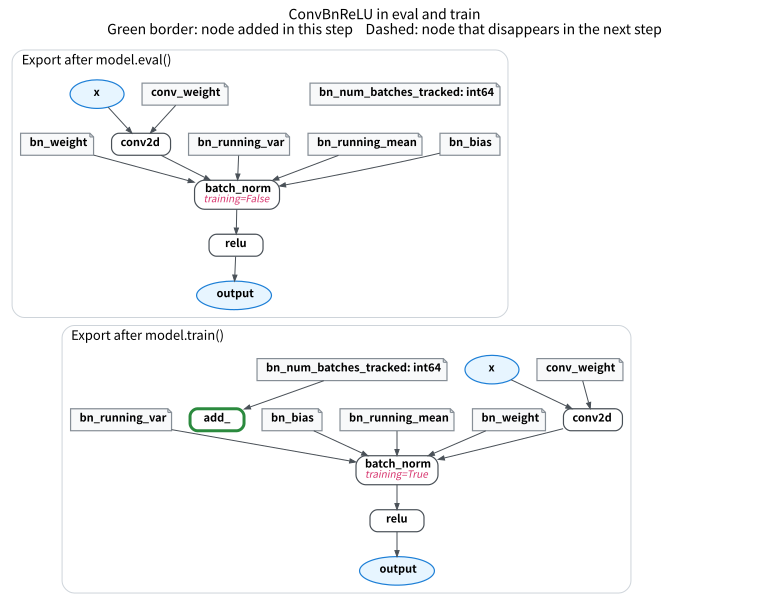

In [4]:
def bn_node(gm):
    return next(n for n in gm.graph.nodes if n.op == "call_function" and "batch_norm" in str(n.target))


BN_ARG_NAMES = ["input", "weight", "bias", "running_mean", "running_var",
                "training", "momentum", "eps", "cudnn_enabled"]
notes = [{"batch_norm": f"training={bn_node(gm).args[BN_ARG_NAMES.index('training')]}"}
         for gm in (gm_eval, gm_train)]
draw_stages([(gm_eval, "Export after model.eval()"), (gm_train, "Export after model.train()")],
            show_params=True, notes=notes, per_row=1, title="ConvBnReLU in eval and train")

- The data flow (conv2d → batch_norm → relu) is the same on both sides, and `batch_norm` is the same op `aten.batch_norm.default`. The difference hides in its `training` argument (shown under the node).
- The extra `add_` in train (green border) reads `bn_num_batches_tracked`: in train mode the BN forward does `num_batches_tracked += 1`, and export records it as an in-place `add_`.
  It has no users, and the output does not depend on it; on the eval side, nobody reads `bn_num_batches_tracked`.

In [5]:
add_node = next(n for n in gm_train.graph.nodes if n.op == "call_function" and n.name.startswith("add_"))
print(f"{add_node.name}{tuple(str(a) for a in add_node.args)}, users = {list(add_node.users)}")
assert add_node.args[0].target == "bn.num_batches_tracked" and not add_node.users

add_('bn_num_batches_tracked', '1'), users = []


What about `running_mean` / `running_var`? There is no node on the graph that updates them, because the update happens **inside** the `batch_norm` op:
with `training=True` it normalizes using this batch's statistics and, at the same time, writes the running stats in place back to the buffers passed in.
`num_batches_tracked += 1` is a line of Python that `nn.BatchNorm.forward` executes before calling the op, so it becomes a separate `add_`.

## B. How the `batch_norm` Arguments Differ

In [6]:
def bn_args(gm):
    return {k: (v.name if isinstance(v, torch.fx.Node) else v) for k, v in zip(BN_ARG_NAMES, bn_node(gm).args)}


ae, at = bn_args(gm_eval), bn_args(gm_train)
table([[k, ae[k], at[k], "✱" if ae[k] != at[k] else ""] for k in BN_ARG_NAMES],
      ["Argument", "gm_eval", "gm_train", "Differs"])

Argument,gm_eval,gm_train,Differs
input,conv2d,conv2d,
weight,bn_weight,bn_weight,
bias,bn_bias,bn_bias,
running_mean,bn_running_mean,bn_running_mean,
running_var,bn_running_var,bn_running_var,
training,False,True,✱
momentum,0.1,0.1,
eps,1e-05,1e-05,
cudnn_enabled,False,False,


In [7]:
assert [k for k in BN_ARG_NAMES if ae[k] != at[k]] == ["training"]

Of the nine arguments only `training` differs. In other words, the mode is fixed on the graph at the moment of export: the `training` argument of `batch_norm`, plus the extra `add_` in train.

So can we still switch with `.train()` / `.eval()` after export?

In [8]:
try:
    gm_eval.train()
    raised = None
except NotImplementedError as e:
    raised = e
print(f"gm_eval.train() → {type(raised).__name__}: {raised}")
assert isinstance(raised, NotImplementedError)

gm_eval.train() → NotImplementedError: Calling train() is not supported yet.


No. The forward of a `GraphModule` is code generated from the graph, and `.train()` cannot change arguments fixed on the graph.
When QAT needs to switch between training and evaluation, use `move_exported_model_to_train` / `move_exported_model_to_eval` (M06); what they do is rewrite these nodes on the graph.

## Summary

- Decide eval or train before export: the mode is written into the graph (the `training` argument of `batch_norm`, and the extra `add_` in train).
- PTQ exports in eval mode so that BN can be folded into the conv at `prepare_pt2e` (M01-1 showed batch_norm disappearing); QAT uses train mode (M04, M06).
- A GraphModule after export can no longer be switched with `.train()` / `.eval()`.